In [1]:
!pip install opencv-python matplotlib

Saving kebun.jpg to kebun.jpg


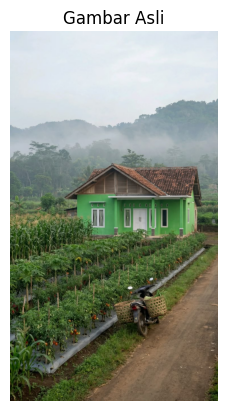

Ukuran gambar: (1308, 736, 3)


In [2]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

nama_file = next(iter(uploaded))

img = cv2.imread(nama_file)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

print("Ukuran gambar:", img.shape)

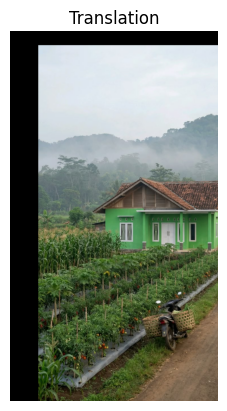

In [3]:
tinggi, lebar = img.shape[:2]

tx = 100
ty = 50

matriks = np.float32([
    [1, 0, tx],
    [0, 1, ty]
])

translation = cv2.warpAffine(
    img, matriks, (lebar, tinggi)
)

plt.imshow(translation)
plt.title("Translation")
plt.axis("off")
plt.show()

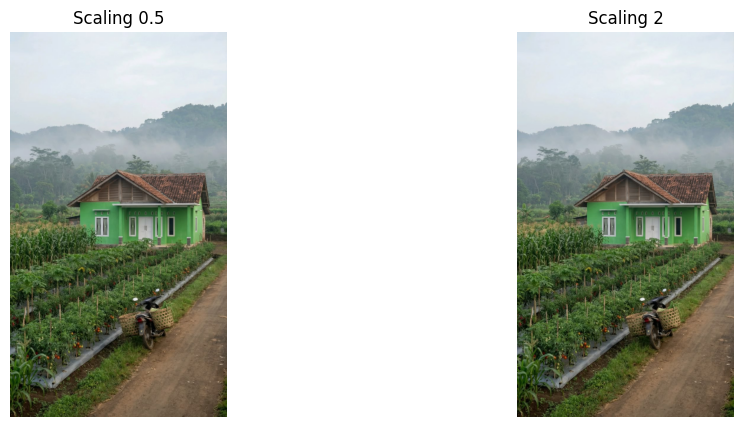

In [4]:
scaling_05 = cv2.resize(
    img, None, fx=0.5, fy=0.5
)

scaling_2 = cv2.resize(
    img, None, fx=2, fy=2
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(scaling_05)
plt.title("Scaling 0.5")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(scaling_2)
plt.title("Scaling 2")
plt.axis("off")

plt.show()

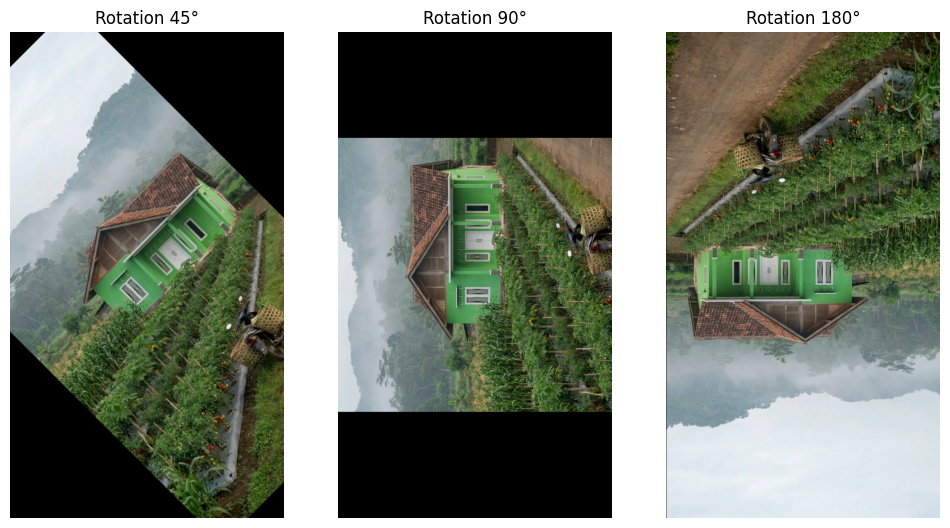

In [5]:
tinggi, lebar = img.shape[:2]

def rotasi(gambar, sudut):
    h, w = gambar.shape[:2]

    pusat = (w // 2, h // 2)

    matriks = cv2.getRotationMatrix2D(
        pusat, sudut, 1.0
    )

    hasil = cv2.warpAffine(
        gambar, matriks, (w, h)
    )

    return hasil

rotation_45 = rotasi(img, 45)
rotation_90 = rotasi(img, 90)
rotation_180 = rotasi(img, 180)

plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(rotation_45)
plt.title("Rotation 45°")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(rotation_90)
plt.title("Rotation 90°")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(rotation_180)
plt.title("Rotation 180°")
plt.axis("off")

plt.show()

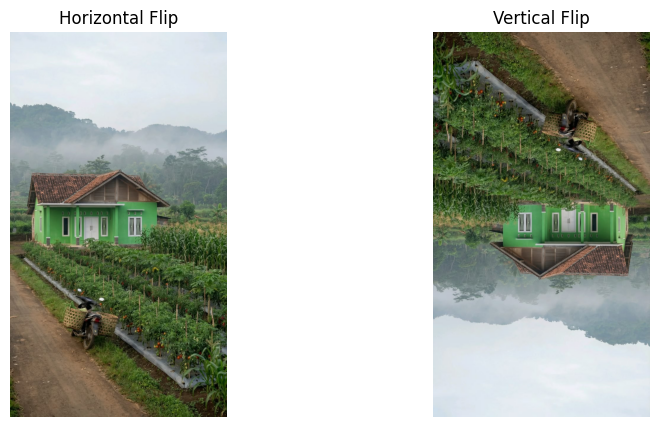

In [6]:
horizontal_flip = cv2.flip(img, 1)

vertical_flip = cv2.flip(img, 0)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(horizontal_flip)
plt.title("Horizontal Flip")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vertical_flip)
plt.title("Vertical Flip")
plt.axis("off")

plt.show()

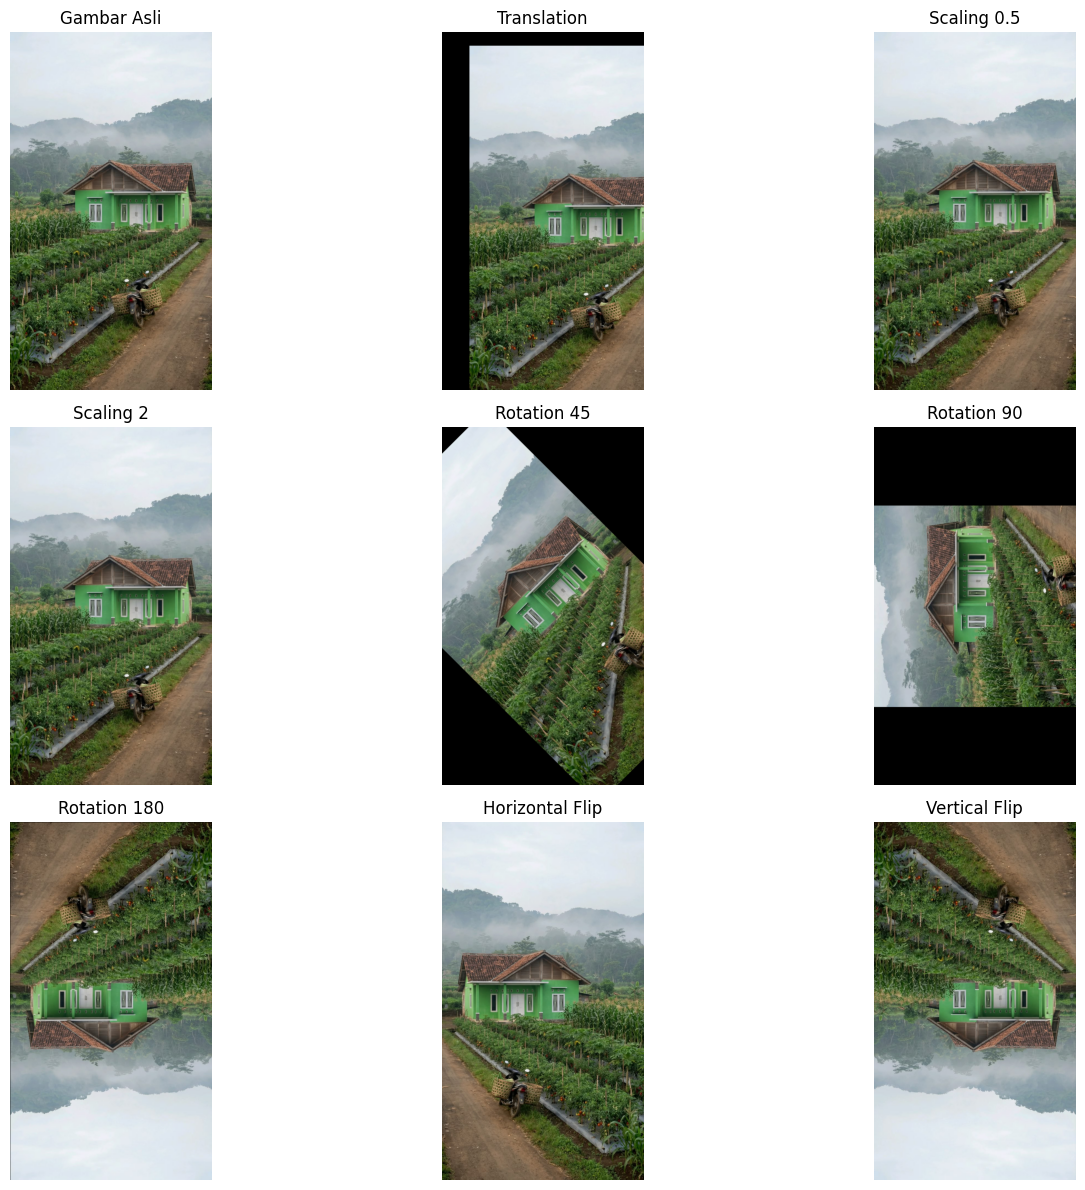

In [7]:
hasil_transformasi = [
    ("Gambar Asli", img),
    ("Translation", translation),
    ("Scaling 0.5", scaling_05),
    ("Scaling 2", scaling_2),
    ("Rotation 45", rotation_45),
    ("Rotation 90", rotation_90),
    ("Rotation 180", rotation_180),
    ("Horizontal Flip", horizontal_flip),
    ("Vertical Flip", vertical_flip)
]

plt.figure(figsize=(15, 12))

for i, (judul, gambar) in enumerate(hasil_transformasi):
    plt.subplot(3, 3, i + 1)
    plt.imshow(gambar)
    plt.title(judul)
    plt.axis("off")

plt.tight_layout()
plt.show()